In [2]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
import random
import warnings
warnings.filterwarnings("ignore")

In [3]:
#load the mnist data
data = np.load('mnist.npz')
print(data.files)

['x_test', 'x_train', 'y_train', 'y_test']


In [4]:
x_train, y_train, x_test, y_test = data['x_train'], data['y_train'], data['x_test'], data['y_test']

In [5]:
#Normalize using min-max range
m, n= np.max(x_train), np.min(x_train)
print(f"max pixel value: {m}")
print(f"min pixel value: {n}")
x_train, x_test = (x_train - n)/(m-n), (x_test - n)/(m-n)

max pixel value: 255
min pixel value: 0


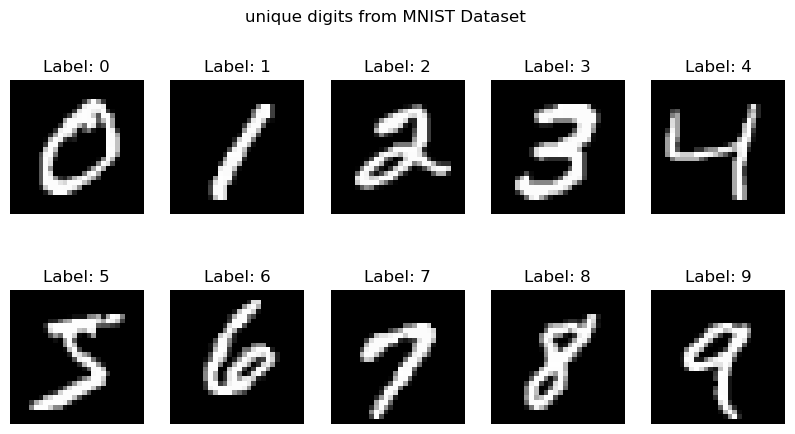

In [6]:
#Visualize unique digits
unique_labels, idx = np.unique(y_train, return_index=True)
fig, ax = plt.subplots(2,5, figsize=(10,5))
for i , label in enumerate(unique_labels):
    ax.flat[i].imshow(x_train[idx[i]], cmap='gray')
    ax.flat[i].set_title(f"Label: {label}")
    ax.flat[i].axis("off")
plt.suptitle("unique digits from MNIST Dataset")
plt.show()

In [7]:
#Build a model
model = keras.Sequential([
    layers.Flatten(input_shape=(28,28)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

In [9]:
#Compile
model.compile(optimizer=keras.optimizers.SGD(learning_rate=0.01), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [12]:
#Train
history = model.fit(x_train, y_train, epochs=10, validation_split=0.2, verbose=2, batch_size=100)

Epoch 1/10
480/480 - 2s - 4ms/step - accuracy: 0.9623 - loss: 0.1231 - val_accuracy: 0.9694 - val_loss: 0.1042
Epoch 2/10
480/480 - 1s - 3ms/step - accuracy: 0.9645 - loss: 0.1187 - val_accuracy: 0.9701 - val_loss: 0.1032
Epoch 3/10
480/480 - 1s - 3ms/step - accuracy: 0.9653 - loss: 0.1156 - val_accuracy: 0.9699 - val_loss: 0.1022
Epoch 4/10
480/480 - 1s - 3ms/step - accuracy: 0.9663 - loss: 0.1133 - val_accuracy: 0.9709 - val_loss: 0.1000
Epoch 5/10
480/480 - 1s - 3ms/step - accuracy: 0.9652 - loss: 0.1128 - val_accuracy: 0.9714 - val_loss: 0.0995
Epoch 6/10
480/480 - 1s - 3ms/step - accuracy: 0.9674 - loss: 0.1082 - val_accuracy: 0.9714 - val_loss: 0.0986
Epoch 7/10
480/480 - 1s - 3ms/step - accuracy: 0.9671 - loss: 0.1067 - val_accuracy: 0.9718 - val_loss: 0.0972
Epoch 8/10
480/480 - 1s - 3ms/step - accuracy: 0.9690 - loss: 0.1040 - val_accuracy: 0.9723 - val_loss: 0.0963
Epoch 9/10
480/480 - 1s - 3ms/step - accuracy: 0.9694 - loss: 0.1025 - val_accuracy: 0.9724 - val_loss: 0.0948
E

In [15]:
#Evaluate
loss, acc= model.evaluate(x_test, y_test, verbose=1)
print(f"accuracy: {acc*100:.2f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9717 - loss: 0.0889 
accuracy: 97.17


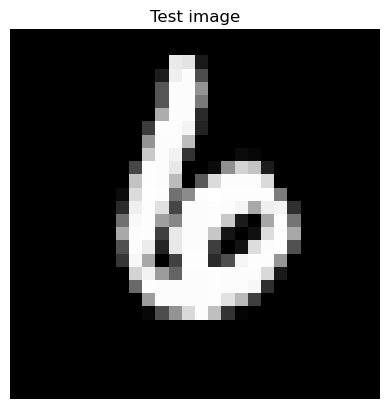

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
predicted digit:  6


In [20]:
#Predict Random test image
n= random.randint(0,len(x_test)-1)
plt.imshow(x_test[n], cmap='gray')
plt.title("Test image")
plt.axis("off")
plt.show()
pred = np.argmax(model.predict(np.expand_dims(x_test[n], axis=0))[0])
print("predicted digit: ", pred)

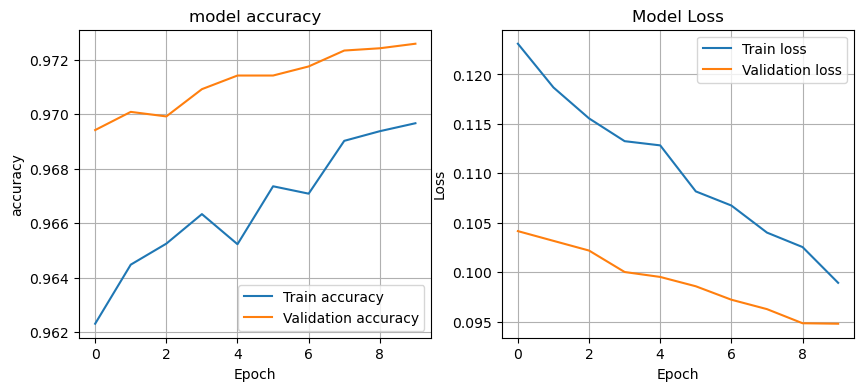

In [24]:
#plot the traning accuracry and validation accuracy
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label= 'Train accuracy')
plt.plot(history.history['val_accuracy'], label = 'Validation accuracy')
plt.title('model accuracy')
plt.xlabel('Epoch')
plt.ylabel('accuracy')
plt.legend()
plt.grid(True)

#plot the traning loss and validation loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label= 'Train loss')
plt.plot(history.history['val_loss'], label = 'Validation loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()